# Cervical — SLC transporter + neighborhood factors ('both')

Views the `factor_group='both'` cervical run (CPM target, n_total_genes covariate, all gene
factors kept). The `view()` / membership / `compare_tcell_factors` sections are shared with
the nbhd notebook; the **interaction-heatmap** section at the end draws **two** heatmaps per
run-spec — one over SLC transporter factors, one over cancer neighborhood factors — from the
same cache. For residual plots of both factor groups, see
`signature_residuals_cervical_both.ipynb`.

In [1]:
import sys
import json
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from metab_processing.LinearRegression import signature_helpers as sh, signature_batch as sb
from metab_processing.LinearRegression.signature_configs import CONFIGS

from dataclasses import replace
# 'both' run: cancer NEIGHBORHOOD factors AND cell-autonomous SLC transporter factors together
# (both live in obsm['x_custom']), CPM target, n_total_genes covariate, all gene factors kept.
# Matches: signature_run.py --config cervical --factor-group both --y-transform cpm --covariates n_total_genes
# (cached under cervical/fg_both/y_cpm__cov_n_total_genes).
cfg = replace(CONFIGS['cervical'], factor_group='both', y_transform='cpm',
              covariates=('n_total_genes',))

# Which ratio plots `view()` renders (keys of sh.plot_res).
PLOTS = ('variance_ratio',)
# ---- Which cached fit to READ (must match a computed params subdir) ----
# Default = this config's fit (l1 @ penalty 0.005). To read a different fit, override, e.g.:
#   READ = dict(method='ridge', penalty=800)
# READ = dict(method=cfg.method, penalty=cfg.penalty, l1_ratio=cfg.l1_ratio)
READ = dict(method='l1', penalty=.005, l1_ratio=cfg.l1_ratio)

## Factor-overlap tools — `compare_tcell_factors(sig)`

Compare which neighborhood factors are **selected** (subsample interval excludes 0) across a
target's T-cell runs. For one signature it prints:

1. the **symmetric difference** of the two pooled runs — *all T cells, no batch* vs *all T
   cells, cell-type (batch) covariate* — one line each direction;
2. per single T-cell type, factors selected in **that type but in neither pooled run**;
3. per pooled run, factors selected there but in **none of the single-type runs**.

Flexible: pass `top_n=` for the top-N by |β|, override the read fit (`method=`, `penalty=`),
or build your own sets and call the core `compare_factor_sets(pooled_nobatch, pooled_batch,
per_type)` for any other definition of "in".

In [2]:
# ======================================================================================
# Factor-overlap tools: compare which factors are SELECTED across a target's T-cell runs.
#
# "Selected" (a factor is "in" a run) = its subsample beta interval excludes 0
# (`sh.filter_nonzero_interval`, touch_zero) -- the same sign-stable test the ratio plots
# highlight. Pass `top_n` to restrict to the top-N selected by |beta|, or build your own
# sets and call the flexible core `compare_factor_sets` directly for any other definition.
#
# The three cervical T-cell run-specs this compares (see `sb.runspecs(cfg)`):
#   'all_pooled'                        -- all T cells pooled, NO covariate      (no batch)
#   f'all_pooled_cov_{cell_type_col}'   -- all T cells pooled, cell-type covariate (batch)
#   f'{ct}_only'  for each ct           -- one single T subtype at a time
# ======================================================================================

def selected_factors(res, *, touch_zero=True, top_n=None):
    """The SELECTED factors of one run's `res`: those whose subsample beta interval excludes
    0 (`sh.filter_nonzero_interval` -- the test the ratio plots highlight). With `top_n`,
    keep only the top-N of those by |beta|. Returns a set of factor names; an empty set for
    a None/empty `res` (e.g. a run not yet computed)."""
    if res is None or len(res) == 0:
        return set()
    sig = sh.filter_nonzero_interval(res, touch_zero=touch_zero)
    if top_n is not None:
        sig = sig.reindex(sig['beta'].abs().sort_values(ascending=False).index).head(top_n)
    return set(sig['factor'])


def compare_factor_sets(pooled_nobatch, pooled_batch, per_type, *,
                        nobatch_name='all T cells (no batch)',
                        batch_name='all T cells (batch cov)'):
    """Flexible comparison of a target's factor sets across its runs -- PRINTS only, returns
    nothing. All three inputs are SETS OF FACTOR NAMES (e.g. from `selected_factors`), so
    this works for any 'in' definition you choose:
        pooled_nobatch -- factors in the all-T-cell run with NO covariate,
        pooled_batch   -- factors in the all-T-cell run WITH the cell-type (batch) covariate,
        per_type       -- {cell_type_name: set of factors} for each single-T-type run.
    It prints:
      (1) how the two pooled runs differ (symmetric difference, one line per direction);
      (2) per cell type, factors in THAT type but in NEITHER pooled run;
      (3) per pooled run, factors in it but in NONE of the single-type runs."""
    def _fmt(s):
        return ', '.join(sorted(s)) if s else '(none)'

    # (1) pooled no-batch vs pooled batch -- symmetric difference, two directions.
    print(f'=== pooled runs differ: {nobatch_name}  vs  {batch_name} ===')
    only_nb = pooled_nobatch - pooled_batch
    only_b = pooled_batch - pooled_nobatch
    print(f'  in {nobatch_name} but NOT {batch_name} ({len(only_nb)}): {_fmt(only_nb)}')
    print(f'  in {batch_name} but NOT {nobatch_name} ({len(only_b)}): {_fmt(only_b)}')

    # (2) per single-type: factors in that type but in NEITHER pooled run.
    pooled_union = pooled_nobatch | pooled_batch
    print(f'\n=== per T-cell type: SELECTED factors not in EITHER pooled run ===')
    for ct, fs in per_type.items():
        extra = fs - pooled_union
        print(f'  {ct} ({len(extra)}): {_fmt(extra)}')

    # (3) per pooled run: factors in it but in NO single-type run.
    per_type_union = set().union(*per_type.values()) if per_type else set()
    print(f'\n=== pooled-only: factors in a pooled run but in NO single-type run ===')
    print(f'  {nobatch_name} ({len(pooled_nobatch - per_type_union)}): '
          f'{_fmt(pooled_nobatch - per_type_union)}')
    print(f'  {batch_name} ({len(pooled_batch - per_type_union)}): '
          f'{_fmt(pooled_batch - per_type_union)}')


def compare_tcell_factors(sig, *, touch_zero=True, top_n=None, **read):
    """Read `sig`'s cervical cache and run `compare_factor_sets` over its T-cell runs:
    all_pooled (no batch), all_pooled_cov_<cell_type_col> (batch covariate), and each
    {ct}_only single-type run. 'In' = selected (subsample interval excludes 0); pass `top_n`
    for the top-N by |beta|. READ params apply; override per-call (e.g. method='ridge',
    penalty=800). Runs not yet computed are warned about and treated as empty."""
    read = {**READ, **read}
    batch_label = f'all_pooled_cov_{cfg.cell_type_col}'
    missing = []

    def sel(label):
        res = sb.load_res(cfg, sig, label, **read)
        if res is None:
            missing.append(label)
        return selected_factors(res, touch_zero=touch_zero, top_n=top_n)

    pooled_nobatch = sel('all_pooled')
    pooled_batch = sel(batch_label)
    per_type = {ct: sel(f'{ct}_only') for ct in cfg.t_cell_types}

    print(f'########## {sig}'
          + (f'  (top_n={top_n})' if top_n is not None else '') + ' ##########')
    if missing:
        print(f'  [not yet computed, treated as empty]: {missing}')
    compare_factor_sets(pooled_nobatch, pooled_batch, per_type)

In [3]:
# Example: compare factor selection across the T-cell runs for one target.
compare_tcell_factors('HALLMARK_IL2_STAT5_SIGNALING')

# Variations:
#   compare_tcell_factors('HALLMARK_IL2_STAT5_SIGNALING', top_n=10)          # top 10 by |beta|
#   compare_tcell_factors('HALLMARK_IL2_STAT5_SIGNALING', method='ridge', penalty=800)


########## HALLMARK_IL2_STAT5_SIGNALING ##########
  [not yet computed, treated as empty]: ['all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (72): ANGPTL4$CDH11, BCL3, BMP2#PITX1, BMP2#SOX11, BRCA1, C3$ITGB2, CCL1$CCR8, CD80$CTLA4, COL6A2$ITGB1, COMP$ITGB1, CTSG$F2RL3, DBX2, ELK3, EZH2, Exhausted T Cells-HALLMARK_KRAS_SIGNALING_UP, FCER2$ITGAV, FGF4$FGFR3, HGF#FOSL1, IL10#CREBZF, IL11#ETV1, IL15$IL2RG, IL18#GSC2, IL1A#BACH1, IL1A$IL1R2, IL1B$IL1R1, IL27#ELK4, IL27#SMARCC2, IL3$IL3RA, IL7#IKZF2, IRF8, IRX3, ITGB1$VCAM1, LTA#E2F4, LYL1, MAFB, MYBL2, NRG1$ERBB4, OR4F17+ Cells-HALLMARK_KRAS_SIGNALING_DN, PBX4, PDGFA#HINFP, PDGFD$PDGFRB, PF4#ZIC4, PRRX1, PRSS2$F2RL3, PTN$SDC3, SETDB1, SLC10A7, SLC12A7, SLC12A9, SLC23A3, SLC25A37, SLC25A40, SLC25A46, SLC30A5, SLC38A3

In [4]:
membership = json.load(open(Path(cfg.cache_dir) / '_membership.json'))
print(f'{cfg.name}: loaded membership for {len(membership)} gene set(s)')

cervical: loaded membership for 35 gene set(s)


## cervical: target signatures -- membership, missing, present, factor-removed, remaining

In [5]:
print(f'===== {cfg.name} target signatures: membership + factor-removal =====')
for name in list(cfg.target_signatures) + list(cfg.neg_controls) + list(cfg.manual_sets):
    m = membership.get(name, {})
    print(f'\n{name}')
    print(f"  present ({len(m.get('present', []))}): {m.get('present', [])}")
    print(f"  missing ({len(m.get('missing', []))}): {m.get('missing', [])}")
    print(f"  total: {m.get('total', 0)}")
    print(f"  factor_removed ({len(m.get('factor_removed', []))}): {m.get('factor_removed', [])}")
    print(f"  remaining ({len(m.get('remaining', []))}): {m.get('remaining', [])}")

===== cervical target signatures: membership + factor-removal =====

HALLMARK_IL2_STAT5_SIGNALING
  present (199): ['ABCB1', 'ADAM19', 'AGER', 'AHCY', 'AHNAK', 'AHR', 'ALCAM', 'AMACR', 'ANXA4', 'APLP1', 'ARL4A', 'BATF', 'BATF3', 'BCL2', 'BCL2L1', 'BHLHE40', 'BMP2', 'BMPR2', 'CA2', 'CAPG', 'CAPN3', 'CASP3', 'CCND2', 'CCND3', 'CCNE1', 'CCR4', 'CD44', 'CD48', 'CD79B', 'CD81', 'CD83', 'CD86', 'CDC42SE2', 'CDC6', 'CDCP1', 'CDKN1C', 'CISH', 'CKAP4', 'COCH', 'COL6A1', 'CSF1', 'CSF2', 'CST7', 'CTLA4', 'CTSZ', 'CXCL10', 'CYFIP1', 'DCPS', 'DENND5A', 'DHRS3', 'DRC1', 'ECM1', 'EEF1AKMT1', 'EMP1', 'ENO3', 'ENPP1', 'EOMES', 'ETFBKMT', 'ETV4', 'F2RL2', 'FAH', 'FGL2', 'FLT3LG', 'FURIN', 'GABARAPL1', 'GADD45B', 'GALM', 'GATA1', 'GBP4', 'GLIPR2', 'GPR65', 'GPR83', 'GPX4', 'GSTO1', 'GUCY1B1', 'HIPK2', 'HK2', 'HOPX', 'HUWE1', 'HYCC2', 'ICOS', 'IFITM3', 'IFNGR1', 'IGF1R', 'IGF2R', 'IKZF2', 'IKZF4', 'IL10', 'IL10RA', 'IL13', 'IL18R1', 'IL1R2', 'IL1RL1', 'IL2RA', 'IL2RB', 'IL3RA', 'IL4R', 'IRF4', 'IRF6', 'IR

## View helper -- `view(sig)` renders every cached run-spec for one signature

In [6]:
TARGETS = sb.all_targets(cfg)   # targets + neg controls + manual sets (+ colon single gene)
specs = sb.runspecs(cfg)


def view(sig):
    for spec in specs:
        res = sb.load_res(cfg, sig, spec['label'], **READ)
        if res is None:
            print('not yet computed:', sig, spec['label'])
            continue
        sh.plot_res(res, highlight_genes=membership.get(sig, {}).get('present', []),
                    title=f"{sig} | {spec['label']}", plots=PLOTS)

## Metabolic targets (predicted like the T-cell signatures)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


not yet computed: HALLMARK_HYPOXIA all_pooled_cov_cell_type
not yet computed: HALLMARK_HYPOXIA Naive & Memory T Cells_only
not yet computed: HALLMARK_HYPOXIA Regulatory T Cells_only
not yet computed: HALLMARK_HYPOXIA Cytotoxic T Cells_only
not yet computed: HALLMARK_HYPOXIA Exhausted T Cells_only
########## HALLMARK_HYPOXIA ##########
  [not yet computed, treated as empty]: ['all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (132): ADIPOQ$ADIPOR2, ADM#IKZF2, ANGPT1#ZIC5, ANGPTL4$CDH11, ATF4, BACH1, BHLHE40, BMP2#ID1, BMP7#ESR2, BMP7$ACVR2B, BRCA1, CCL27#OTX1, CD48$CD244, CEBPB, CEBPD, CNTF#ERF, CNTF#ZBTB6, COL6A2$CD44, CREB3L1, CSF2#ATOH8, CSF2#MZF1, CUX1, CXCL12#HES2, CXCL8$ACKR1, Cytotoxic T Cells-HALLMARK_HYPOXIA, Cytotoxic T Cells-HALLMARK_OXIDATIVE_PHOSPHORY

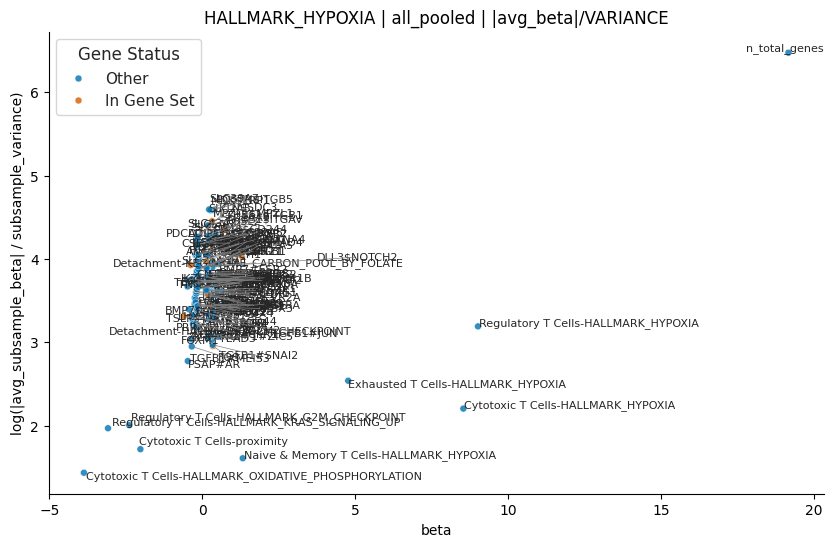

In [7]:
view('HALLMARK_HYPOXIA')
compare_tcell_factors('HALLMARK_HYPOXIA')

In [8]:
view('HALLMARK_GLYCOLYSIS')
compare_tcell_factors('HALLMARK_GLYCOLYSIS')

not yet computed: HALLMARK_GLYCOLYSIS all_pooled
not yet computed: HALLMARK_GLYCOLYSIS all_pooled_cov_cell_type
not yet computed: HALLMARK_GLYCOLYSIS Naive & Memory T Cells_only
not yet computed: HALLMARK_GLYCOLYSIS Regulatory T Cells_only
not yet computed: HALLMARK_GLYCOLYSIS Cytotoxic T Cells_only
not yet computed: HALLMARK_GLYCOLYSIS Exhausted T Cells_only
########## HALLMARK_GLYCOLYSIS ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T Cells (0): (none)
  Regulatory T Cells (0): (none)
  Cytotoxic T Cells (0): (none)
  Exhaust

In [9]:
view('HALLMARK_OXIDATIVE_PHOSPHORYLATION')
compare_tcell_factors('HALLMARK_OXIDATIVE_PHOSPHORYLATION')

not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION all_pooled
not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION all_pooled_cov_cell_type
not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION Naive & Memory T Cells_only
not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION Regulatory T Cells_only
not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION Cytotoxic T Cells_only
not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION Exhausted T Cells_only
########## HALLMARK_OXIDATIVE_PHOSPHORYLATION ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naiv

In [10]:
view('HALLMARK_FATTY_ACID_METABOLISM')
compare_tcell_factors('HALLMARK_FATTY_ACID_METABOLISM')

not yet computed: HALLMARK_FATTY_ACID_METABOLISM all_pooled
not yet computed: HALLMARK_FATTY_ACID_METABOLISM all_pooled_cov_cell_type
not yet computed: HALLMARK_FATTY_ACID_METABOLISM Naive & Memory T Cells_only
not yet computed: HALLMARK_FATTY_ACID_METABOLISM Regulatory T Cells_only
not yet computed: HALLMARK_FATTY_ACID_METABOLISM Cytotoxic T Cells_only
not yet computed: HALLMARK_FATTY_ACID_METABOLISM Exhausted T Cells_only
########## HALLMARK_FATTY_ACID_METABOLISM ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T Cells (0): (non

not yet computed: HALLMARK_MTORC1_SIGNALING all_pooled_cov_cell_type
not yet computed: HALLMARK_MTORC1_SIGNALING Naive & Memory T Cells_only
not yet computed: HALLMARK_MTORC1_SIGNALING Regulatory T Cells_only
not yet computed: HALLMARK_MTORC1_SIGNALING Cytotoxic T Cells_only
not yet computed: HALLMARK_MTORC1_SIGNALING Exhausted T Cells_only
########## HALLMARK_MTORC1_SIGNALING ##########
  [not yet computed, treated as empty]: ['all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (108): ADM#NR6A1, APP#SCRT1, BMP2#MSX1, BMP4#BARX2, BRCA1, CCL1$CCR8, COL4A3$ITGA11, CXCL12$CXCR4, DHH$PTCH1, E2F1, E2F2, EBI3#DRGX, EBI3#NPAS3, EBI3#PRDM14, EHF, EZH2, FGF2#ETS2, FGF23#ISX, FOXD4L5, FOXM1, GDNF#BARX1, HDAC2, HGF#NFKB1, HLA-E$KLRD1, HMGA1, ICAM1$ITGAL, IFNB1#NEUROD1, IFNG#

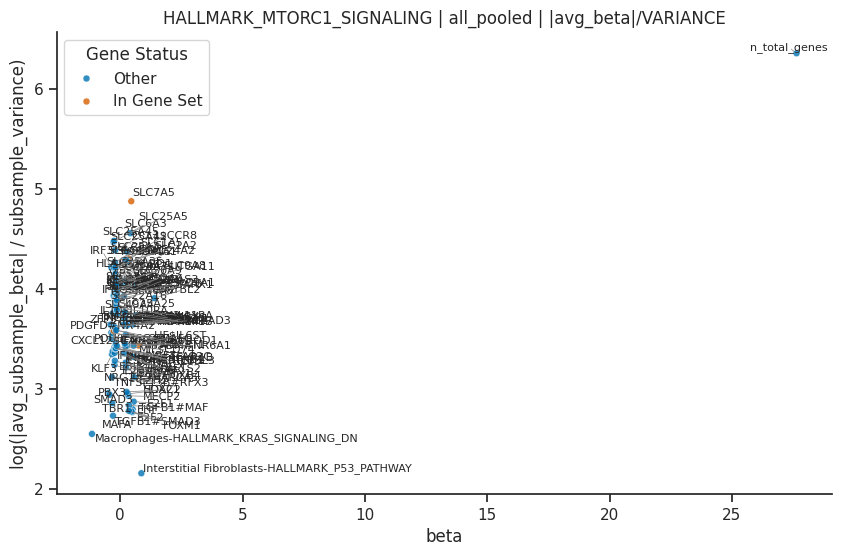

In [11]:
view('HALLMARK_MTORC1_SIGNALING')
compare_tcell_factors('HALLMARK_MTORC1_SIGNALING')

## Subsample stats from cached raw betas -- call `stats('SIGNATURE_NAME')`

In [12]:
# 95% CI / selection-frequency / stability, computed directly from the cached raw subsample
# betas. (CI at n_sub resamples is coarse; under L1 betas pile at 0 so selection_freq + a
# CI excluding 0 are the honest signals, p_stability is a conservative heuristic.)
from IPython.display import display

def stats(sig):
    for spec in specs:
        betas = sb.load_betas(cfg, sig, spec['label'], **READ)
        if betas is None:
            print('not yet computed:', sig, spec['label']); continue
        print(f"\n=== {sig} | {spec['label']} ===")
        display(sh.subsample_stats(betas).sort_values('selection_freq', ascending=False).head(25))

## T-cell TARGET signatures

### HALLMARK_IL2_STAT5_SIGNALING

not yet computed: HALLMARK_IL2_STAT5_SIGNALING all_pooled_cov_cell_type
not yet computed: HALLMARK_IL2_STAT5_SIGNALING Naive & Memory T Cells_only
not yet computed: HALLMARK_IL2_STAT5_SIGNALING Regulatory T Cells_only
not yet computed: HALLMARK_IL2_STAT5_SIGNALING Cytotoxic T Cells_only
not yet computed: HALLMARK_IL2_STAT5_SIGNALING Exhausted T Cells_only
########## HALLMARK_IL2_STAT5_SIGNALING ##########
  [not yet computed, treated as empty]: ['all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (72): ANGPTL4$CDH11, BCL3, BMP2#PITX1, BMP2#SOX11, BRCA1, C3$ITGB2, CCL1$CCR8, CD80$CTLA4, COL6A2$ITGB1, COMP$ITGB1, CTSG$F2RL3, DBX2, ELK3, EZH2, Exhausted T Cells-HALLMARK_KRAS_SIGNALING_UP, FCER2$ITGAV, FGF4$FGFR3, HGF#FOSL1, IL10#CREBZF, IL11#ETV1, IL15$IL2RG, IL18#GS

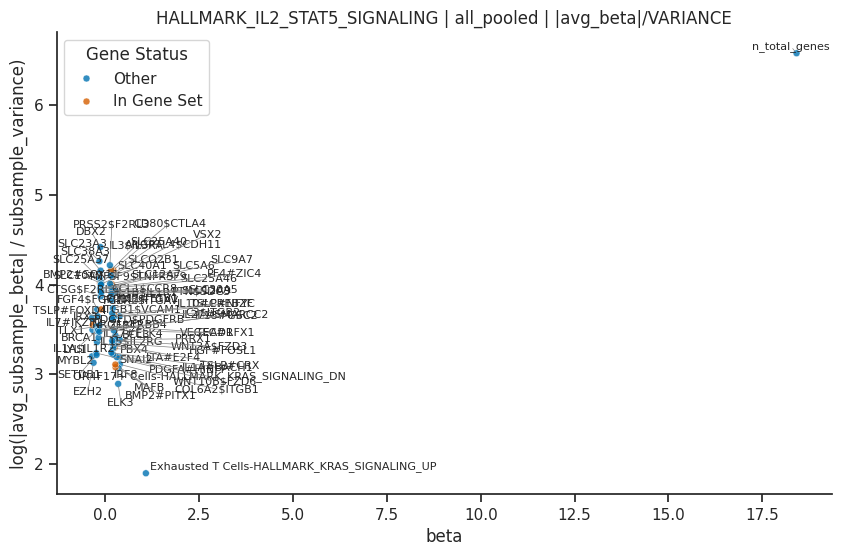

In [13]:
view('HALLMARK_IL2_STAT5_SIGNALING')
compare_tcell_factors('HALLMARK_IL2_STAT5_SIGNALING')

### KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY

In [14]:
view('KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY')
compare_tcell_factors('KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY')

not yet computed: KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY all_pooled
not yet computed: KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY all_pooled_cov_cell_type
not yet computed: KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY Naive & Memory T Cells_only
not yet computed: KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY Regulatory T Cells_only
not yet computed: KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY Cytotoxic T Cells_only
not yet computed: KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY Exhausted T Cells_only
########## KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in 

### GOBP_T_CELL_MEDIATED_CYTOTOXICITY

In [15]:
view('GOBP_T_CELL_MEDIATED_CYTOTOXICITY')
compare_tcell_factors('GOBP_T_CELL_MEDIATED_CYTOTOXICITY')

not yet computed: GOBP_T_CELL_MEDIATED_CYTOTOXICITY all_pooled
not yet computed: GOBP_T_CELL_MEDIATED_CYTOTOXICITY all_pooled_cov_cell_type
not yet computed: GOBP_T_CELL_MEDIATED_CYTOTOXICITY Naive & Memory T Cells_only
not yet computed: GOBP_T_CELL_MEDIATED_CYTOTOXICITY Regulatory T Cells_only
not yet computed: GOBP_T_CELL_MEDIATED_CYTOTOXICITY Cytotoxic T Cells_only
not yet computed: GOBP_T_CELL_MEDIATED_CYTOTOXICITY Exhausted T Cells_only
########## GOBP_T_CELL_MEDIATED_CYTOTOXICITY ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Mem

### KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY

In [16]:
view('KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY')
compare_tcell_factors('KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY')

not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY all_pooled
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY all_pooled_cov_cell_type
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Naive & Memory T Cells_only
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Regulatory T Cells_only
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Cytotoxic T Cells_only
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Exhausted T Cells_only
########## KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0

### HALLMARK_TNFA_SIGNALING_VIA_NFKB

In [17]:
view('HALLMARK_TNFA_SIGNALING_VIA_NFKB')
compare_tcell_factors('HALLMARK_TNFA_SIGNALING_VIA_NFKB')

not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB all_pooled
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB all_pooled_cov_cell_type
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Naive & Memory T Cells_only
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Regulatory T Cells_only
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Cytotoxic T Cells_only
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Exhausted T Cells_only
########## HALLMARK_TNFA_SIGNALING_VIA_NFKB ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T C

### HALLMARK_INTERFERON_GAMMA_RESPONSE

not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE all_pooled_cov_cell_type
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Naive & Memory T Cells_only
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Regulatory T Cells_only
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Cytotoxic T Cells_only
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Exhausted T Cells_only
########## HALLMARK_INTERFERON_GAMMA_RESPONSE ##########
  [not yet computed, treated as empty]: ['all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (178): ADM#ARX, ADM#IRX2, ANGPTL4#MYBL1, ARID5A, ARNT2, B Cells-KEGG_CITRATE_CYCLE_TCA_CYCLE, B Cells-VESSEL_PECAM1, BBX, BDNF#SOX11, BMP4#GATA4, BRCA1, CCL14$ACKR2, CCL19#RARB, CCL3$CCR5, CD274#GFI1, CD40LG$CD40, CD6#ONECUT1, COL4A1$IT

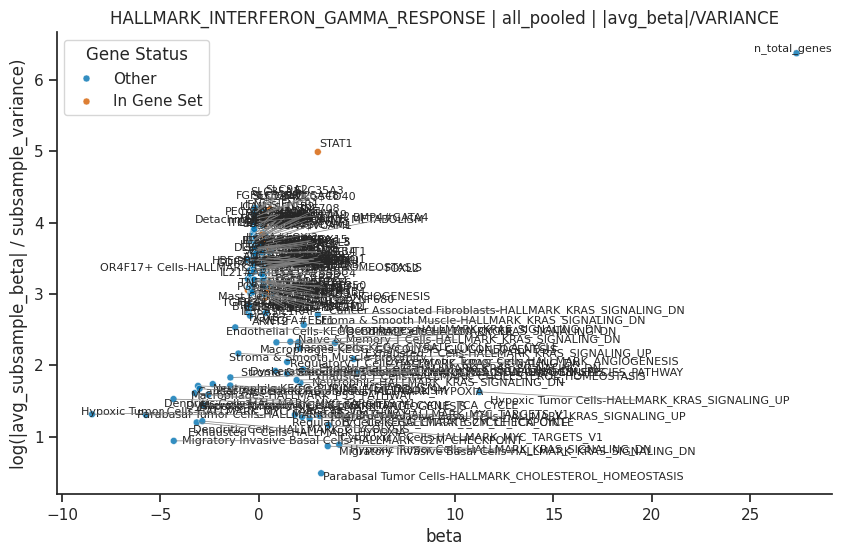

In [18]:
view('HALLMARK_INTERFERON_GAMMA_RESPONSE')
compare_tcell_factors('HALLMARK_INTERFERON_GAMMA_RESPONSE')

### HALLMARK_INTERFERON_ALPHA_RESPONSE

In [19]:
view('HALLMARK_INTERFERON_ALPHA_RESPONSE')
compare_tcell_factors('HALLMARK_INTERFERON_ALPHA_RESPONSE')

not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE all_pooled
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE all_pooled_cov_cell_type
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Naive & Memory T Cells_only
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Regulatory T Cells_only
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Cytotoxic T Cells_only
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Exhausted T Cells_only
########## HALLMARK_INTERFERON_ALPHA_RESPONSE ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naiv

### GOBP_CELL_KILLING

In [20]:
view('GOBP_CELL_KILLING')
compare_tcell_factors('GOBP_CELL_KILLING')

not yet computed: GOBP_CELL_KILLING all_pooled
not yet computed: GOBP_CELL_KILLING all_pooled_cov_cell_type
not yet computed: GOBP_CELL_KILLING Naive & Memory T Cells_only
not yet computed: GOBP_CELL_KILLING Regulatory T Cells_only
not yet computed: GOBP_CELL_KILLING Cytotoxic T Cells_only
not yet computed: GOBP_CELL_KILLING Exhausted T Cells_only
########## GOBP_CELL_KILLING ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T Cells (0): (none)
  Regulatory T Cells (0): (none)
  Cytotoxic T Cells (0): (none)
  Exhausted T Cells (0)

### GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY

In [21]:
view('GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY')
compare_tcell_factors('GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY')

not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY all_pooled
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY all_pooled_cov_cell_type
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Naive & Memory T Cells_only
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Regulatory T Cells_only
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Cytotoxic T Cells_only
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Exhausted T Cells_only
########## GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no b

### GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY

In [22]:
view('GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY')
compare_tcell_factors('GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY')

not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY all_pooled
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY all_pooled_cov_cell_type
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Naive & Memory T Cells_only
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Regulatory T Cells_only
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Cytotoxic T Cells_only
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Exhausted T Cells_only
########## GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Mem

## Negative controls

### HALLMARK_PANCREAS_BETA_CELLS

In [23]:
view('HALLMARK_PANCREAS_BETA_CELLS')
compare_tcell_factors('HALLMARK_PANCREAS_BETA_CELLS')

not yet computed: HALLMARK_PANCREAS_BETA_CELLS all_pooled
not yet computed: HALLMARK_PANCREAS_BETA_CELLS all_pooled_cov_cell_type
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Naive & Memory T Cells_only
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Regulatory T Cells_only
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Cytotoxic T Cells_only
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Exhausted T Cells_only
########## HALLMARK_PANCREAS_BETA_CELLS ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T Cells (0): (none)
  Regulator

### HALLMARK_SPERMATOGENESIS

In [24]:
view('HALLMARK_SPERMATOGENESIS')
compare_tcell_factors('HALLMARK_SPERMATOGENESIS')

not yet computed: HALLMARK_SPERMATOGENESIS all_pooled
not yet computed: HALLMARK_SPERMATOGENESIS all_pooled_cov_cell_type
not yet computed: HALLMARK_SPERMATOGENESIS Naive & Memory T Cells_only
not yet computed: HALLMARK_SPERMATOGENESIS Regulatory T Cells_only
not yet computed: HALLMARK_SPERMATOGENESIS Cytotoxic T Cells_only
not yet computed: HALLMARK_SPERMATOGENESIS Exhausted T Cells_only
########## HALLMARK_SPERMATOGENESIS ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T Cells (0): (none)
  Regulatory T Cells (0): (none)
  Cyto

## MANUAL_ISLET_NEG_CONTROL (manual negative control)

In [25]:
view('MANUAL_ISLET_NEG_CONTROL')
compare_tcell_factors('MANUAL_ISLET_NEG_CONTROL')

not yet computed: MANUAL_ISLET_NEG_CONTROL all_pooled
not yet computed: MANUAL_ISLET_NEG_CONTROL all_pooled_cov_cell_type
not yet computed: MANUAL_ISLET_NEG_CONTROL Naive & Memory T Cells_only
not yet computed: MANUAL_ISLET_NEG_CONTROL Regulatory T Cells_only
not yet computed: MANUAL_ISLET_NEG_CONTROL Cytotoxic T Cells_only
not yet computed: MANUAL_ISLET_NEG_CONTROL Exhausted T Cells_only
########## MANUAL_ISLET_NEG_CONTROL ##########
  [not yet computed, treated as empty]: ['all_pooled', 'all_pooled_cov_cell_type', 'Naive & Memory T Cells_only', 'Regulatory T Cells_only', 'Cytotoxic T Cells_only', 'Exhausted T Cells_only']
=== pooled runs differ: all T cells (no batch)  vs  all T cells (batch cov) ===
  in all T cells (no batch) but NOT all T cells (batch cov) (0): (none)
  in all T cells (batch cov) but NOT all T cells (no batch) (0): (none)

=== per T-cell type: SELECTED factors not in EITHER pooled run ===
  Naive & Memory T Cells (0): (none)
  Regulatory T Cells (0): (none)
  Cyto

## Interaction heatmaps — (target signature × factor) pairings, SLC **and** neighborhood

Each cell = ONE **(target signature, factor) pairing**: the regression coefficient (`beta`,
full fit) of that custom factor when predicting the target. **Load** builds a tidy
one-row-per-pairing table from the cache (all factors); the driver then draws, **per cervical
run-spec**, a heatmap over the **cancer neighborhood** factors (`is_nbhd_factor`, the
`{celltype}-{SET}` columns) and a heatmap over the **SLC transporter** factors
(`is_slc_factor`, names matching `cfg.slc_pattern`) — both from the SAME `factor_group='both'`
cache.

**Stars = how robustly the pairing's coefficient stays one-signed across the subsample
refits** (`min_trim` = smallest number of extreme subsamples dropped from EACH end before the
remaining range excludes 0): ★★★ `min_trim` 0; ★★ drop 1/side; ★ drop 2/side. Significant =
≥ `min_stars` (default 1). `inspect_pair(target, factor)` shows the trimmed bounds behind any
cell. **Cervical has multiple run-specs**, so one SEPARATE heatmap is drawn per run.

In [26]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RUN_LABEL = 'all_pooled'   # cervical default; driver loops all runs
HEAT_READ = dict(READ)                       # which cached fit to read (see READ, top of nb)
Y_TARGETS = list(cfg.target_signatures) + list(cfg.neg_controls) + list(cfg.manual_sets)


def _min_trim_to_exclude(b):
    """Smallest number of extreme points to drop from EACH end of a factor's subsample betas
    before the remaining range excludes 0 (strictly one-signed). 0 = the full set never
    crosses/touches 0; np.inf = still crosses even trimmed to the center. (Monotonic: once an
    interval is one-signed, trimming further keeps it one-signed.) NaN subsamples dropped."""
    b = np.asarray(b, dtype=float); b = b[~np.isnan(b)]
    n = b.size
    if n == 0:
        return np.nan
    s = np.sort(b)
    for t in range((n - 1) // 2 + 1):
        if s[t] > 0 or s[-(t + 1)] < 0:
            return float(t)
    return np.inf


def load_interactions(targets=None, label=RUN_LABEL, **read):
    """Tidy one-row-per-(target, factor) table for ONE run `label`, from the cache. Columns:
    target, factor, beta (full-fit coefficient = plotted value), the subsample CI summary
    from `res`, and `min_trim` (from the raw per-subsample beta sidecar `load_betas`). If the
    sidecar is absent, `min_trim` falls back to 0 when res's full range [min,max] excludes 0
    else NaN -- so only the 3-star 'no crossing' level is distinguishable then."""
    read = {**HEAT_READ, **read}
    targets = Y_TARGETS if targets is None else targets
    out = []
    for t in targets:
        res = sb.load_res(cfg, t, label, **read)
        if res is None:
            print('skip (no cached res):', t, '|', label); continue
        r = res.copy(); r.insert(0, 'target', t); r['run'] = label
        betas = sb.load_betas(cfg, t, label, **read)
        if betas is not None:
            mt = {f: _min_trim_to_exclude(betas[f].to_numpy()) for f in betas.columns}
            r['min_trim'] = r['factor'].map(mt)
        elif 'min_subsample_beta' in r.columns:
            lo, hi = r['min_subsample_beta'], r['max_subsample_beta']
            r['min_trim'] = np.where((lo > 0) | (hi < 0), 0.0, np.nan)
        else:
            r['min_trim'] = np.nan
        out.append(r)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()


In [27]:
import re
# Two x-axis factor families, both drawn from the SAME cached res under factor_group='both':
#   NEIGHBORHOOD -- the '{celltype}-{SET}' custom columns (cancer gene sets + vessel marker);
#                   excludes the '*_proximity' controls.
#   SLC          -- the cell-autonomous SLC transporter custom columns, i.e. factor names that
#                   fully match cfg.slc_pattern (exactly how add_slc_factors selected them).
CANCER_SETS = list(cfg.cancer_factors) + list(cfg.vessel)
_SLC_RE = re.compile(cfg.slc_pattern)

def is_cancer_set(factor):
    return any(str(factor).endswith('-' + s) for s in CANCER_SETS)

def is_nbhd_factor(factor):            # alias -- neighborhood factors are the cancer sets
    return is_cancer_set(factor)

def is_slc_factor(factor):
    return bool(_SLC_RE.match(str(factor)))


def default_stars(row):
    """Stars from `min_trim` (smallest #subsamples dropped from each end before the interval
    excludes 0):
       3 = min_trim 0   -> no subsample crosses/touches 0 (full range one-signed)
       2 = min_trim <= 1 -> excludes 0 after dropping the top-1 and bottom-1 subsample
       1 = min_trim <= 2 -> excludes 0 after dropping the top-2 and bottom-2
       else 0.  Change the cutoffs with your own `stars=`(row -> int), e.g.
       stars=lambda r: 3 if r['min_trim']==0 else 2 if r['min_trim']<=3 else 1 if r['min_trim']<=5 else 0"""
    m = row.get('min_trim')
    if pd.isna(m):
        return 0
    if m <= 0:
        return 3
    if m <= 1:
        return 2
    if m <= 2:
        return 1
    return 0


def inspect_pair(target, factor, label=RUN_LABEL, **read):
    """Everything behind ONE (target, factor) cell: point beta, and -- from the raw subsample
    sidecar -- the sign counts, `min_trim`, and the trimmed bounds at drop 0/1/2 per side.
    Falls back to the res interval when the sidecar is absent. Returns the res row."""
    read = {**HEAT_READ, **read}
    res = sb.load_res(cfg, target, label, **read)
    if res is None:
        print('no cached res for', target, '|', label); return
    sub = res[res['factor'] == factor]
    if sub.empty:
        print(factor, 'is not a factor of', target, '| run', label); return
    row = sub.iloc[0]
    print(f"{target}  x  {factor}   (run={label})")
    print(f"  beta={row['beta']:+.4g}")
    betas = sb.load_betas(cfg, target, label, **read)
    if betas is not None and factor in betas.columns:
        b = betas[factor].to_numpy(dtype=float); b = b[~np.isnan(b)]; s = np.sort(b)
        mt = _min_trim_to_exclude(b)
        print(f"  n_sub={b.size}  zero={(b==0).sum()} pos={(b>0).sum()} neg={(b<0).sum()}  min_trim={mt}")
        for t in (0, 1, 2):
            if b.size >= 2 * t + 1:
                lo, hi = s[t], s[-(t + 1)]
                print(f"    drop {t}/side -> [{lo:+.3g}, {hi:+.3g}]  "
                      f"{'excludes 0' if (lo > 0 or hi < 0) else 'crosses 0'}")
        print(f"  => stars={default_stars({'min_trim': mt})}")
    else:
        lo = row.get('min_subsample_beta'); hi = row.get('max_subsample_beta')
        mt = 0.0 if (pd.notna(lo) and pd.notna(hi) and (lo > 0 or hi < 0)) else np.nan
        print("  (no raw-beta sidecar; only the 3-star 'no crossing' level is knowable from res)")
        print(f"  => stars={default_stars({'min_trim': mt})}")
    return row


def interaction_heatmap(inter, value='beta', *, stars=default_stars, min_stars=1,
                        only_significant_factors=True, factor_filter=is_cancer_set,
                        factor_label='cancer factor signature',
                        log=False, figsize=None, cmap='RdBu_r', title='',
                        star_legend='3=no crossing, 2=drop1/side, 1=drop2/side'):
    """Heatmap of (target x factor) pairings colored by `value` (default point beta). The
    x-axis factor family is chosen by `factor_filter` (is_slc_factor | is_nbhd_factor), and
    `factor_label` names that axis.
    `stars`(row->0..3) rates each pairing; `only_significant_factors` keeps only x-factors
    reaching `min_stars` somewhere (all of them -- no cap). `log` = sign(v)*log1p(|v|). NaN
    pairings render grey. Returns (value_matrix, stars_matrix)."""
    df = inter[inter['factor'].map(factor_filter)].copy()
    if df.empty:
        print('no factors pass factor_filter; nothing to plot'); return
    df['_stars'] = df.apply(stars, axis=1).astype(int)

    val = df.pivot_table(index='target', columns='factor', values=value, aggfunc='first')
    st = (df.pivot_table(index='target', columns='factor', values='_stars', aggfunc='first')
            .reindex(index=val.index, columns=val.columns).fillna(0).astype(int))
    if only_significant_factors:
        keep = (st >= min_stars).any(axis=0)
        val, st = val.loc[:, keep], st.loc[:, keep]
    if val.shape[1] == 0:
        print('no factor reaches min_stars=%d; loosen it or only_significant_factors=False'
              % min_stars); return

    M = val.to_numpy(dtype=float)
    if log:
        M = np.sign(M) * np.log1p(np.abs(M))
    vmax = float(np.nanmax(np.abs(M))) if np.isfinite(M).any() else 1.0
    cmap_obj = plt.get_cmap(cmap).copy(); cmap_obj.set_bad('lightgrey')
    figsize = figsize or (max(10, 0.8 * val.shape[1]), max(6, 0.5 * val.shape[0]))
    with plt.style.context('default'):   # isolate from the global seaborn theme
        fig, ax = plt.subplots(figsize=figsize)
        im = ax.imshow(np.ma.masked_invalid(M), aspect='auto', cmap=cmap_obj, vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(val.shape[1])); ax.set_xticklabels(val.columns, rotation=45, ha='right', fontsize=7)
        ax.set_yticks(range(val.shape[0])); ax.set_yticklabels(val.index, fontsize=8)
        ax.set_xlabel(factor_label); ax.set_ylabel('T-cell target signature')
        ax.set_title(f"{title + '  |  ' if title else ''}{value}"
                     f"{' (signed log1p)' if log else ''}   "
                     f"(stars: {star_legend})")
        S = st.to_numpy()
        for i in range(S.shape[0]):
            for j in range(S.shape[1]):
                if S[i, j] > 0:
                    ax.text(j, i, '*' * int(S[i, j]), ha='center', va='center',
                            fontsize=8, color='black')
        fig.colorbar(im, ax=ax, shrink=0.7, label=value)
        plt.tight_layout(); plt.show()
    return val, st

def interaction_heatmaps(targets=None, specs=None, *, group_label='', **kw):
    """One SEPARATE heatmap per cervical run-spec: all_pooled (no batch),
    all_pooled_cov_cell_type (batch covariate), and each {subtype}_only. `group_label`
    prefixes each title (e.g. 'SLC' / 'nbhd'); kw (factor_filter/factor_label/value/
    min_stars/stars/log/...) apply to every run."""
    specs = sb.runspecs(cfg) if specs is None else specs
    for spec in specs:
        inter = load_interactions(targets=targets, label=spec['label'])
        if inter.empty:
            print('no cached data for run:', spec['label']); continue
        ttl = f"{group_label}  |  {spec['label']}" if group_label else spec['label']
        interaction_heatmap(inter, title=ttl, **kw)

############################################################################
# NEIGHBORHOOD (cancer) factors
############################################################################
skip (no cached res): KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY | all_pooled
skip (no cached res): GOBP_T_CELL_MEDIATED_CYTOTOXICITY | all_pooled
skip (no cached res): KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY | all_pooled
skip (no cached res): HALLMARK_TNFA_SIGNALING_VIA_NFKB | all_pooled
skip (no cached res): HALLMARK_INTERFERON_ALPHA_RESPONSE | all_pooled
skip (no cached res): GOBP_CELL_KILLING | all_pooled
skip (no cached res): GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY | all_pooled
skip (no cached res): GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY | all_pooled


skip (no cached res): HALLMARK_GLYCOLYSIS | all_pooled
skip (no cached res): HALLMARK_OXIDATIVE_PHOSPHORYLATION | all_pooled
skip (no cached res): HALLMARK_FATTY_ACID_METABOLISM | all_pooled
skip (no cached res): HALLMARK_PANCREAS_BETA_CELLS | all_pooled
skip (no cached res): HALLMARK_SPERMATOGENESIS | all_pooled
skip (no cached res): MANUAL_ISLET_NEG_CONTROL | all_pooled


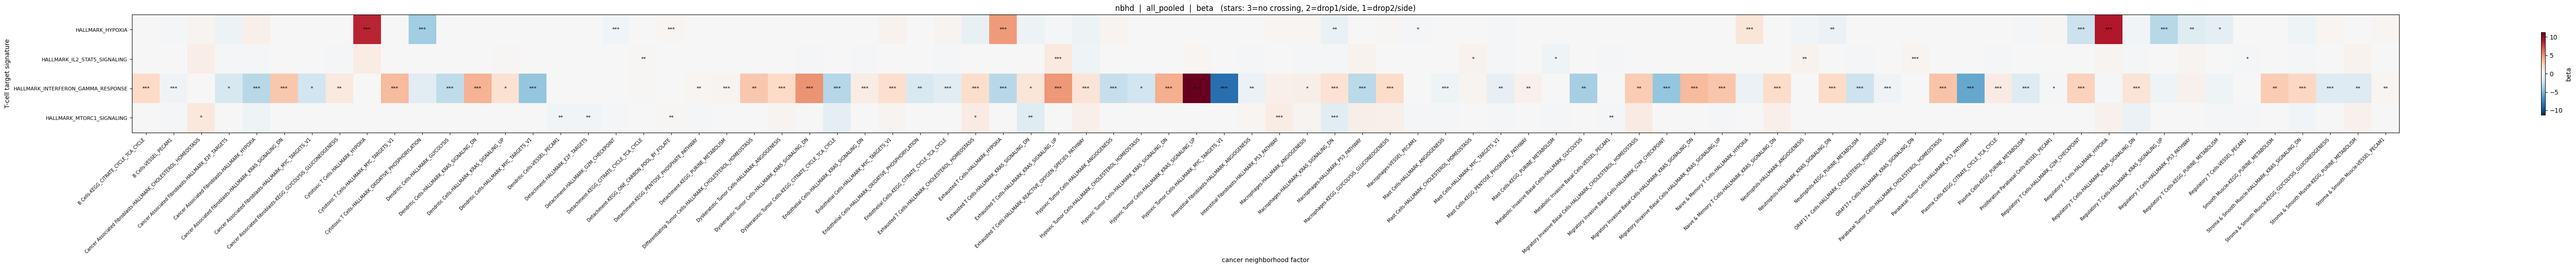

skip (no cached res): HALLMARK_IL2_STAT5_SIGNALING | all_pooled_cov_cell_type
skip (no cached res): KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY | all_pooled_cov_cell_type
skip (no cached res): GOBP_T_CELL_MEDIATED_CYTOTOXICITY | all_pooled_cov_cell_type
skip (no cached res): KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_TNFA_SIGNALING_VIA_NFKB | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_INTERFERON_GAMMA_RESPONSE | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_INTERFERON_ALPHA_RESPONSE | all_pooled_cov_cell_type
skip (no cached res): GOBP_CELL_KILLING | all_pooled_cov_cell_type
skip (no cached res): GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY | all_pooled_cov_cell_type
skip (no cached res): GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_HYPOXIA | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_GLYCOLYSIS | all_pooled_cov_cell_type
skip (no

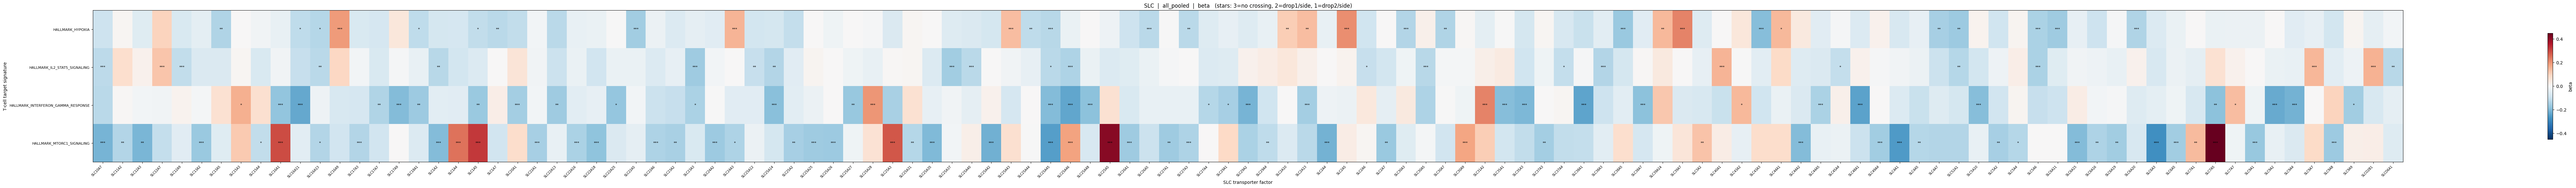

skip (no cached res): HALLMARK_IL2_STAT5_SIGNALING | all_pooled_cov_cell_type
skip (no cached res): KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY | all_pooled_cov_cell_type
skip (no cached res): GOBP_T_CELL_MEDIATED_CYTOTOXICITY | all_pooled_cov_cell_type
skip (no cached res): KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_TNFA_SIGNALING_VIA_NFKB | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_INTERFERON_GAMMA_RESPONSE | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_INTERFERON_ALPHA_RESPONSE | all_pooled_cov_cell_type
skip (no cached res): GOBP_CELL_KILLING | all_pooled_cov_cell_type
skip (no cached res): GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY | all_pooled_cov_cell_type
skip (no cached res): GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_HYPOXIA | all_pooled_cov_cell_type
skip (no cached res): HALLMARK_GLYCOLYSIS | all_pooled_cov_cell_type
skip (no

In [28]:
# Per run-spec: a NEIGHBORHOOD-factor heatmap and an SLC-factor heatmap (all T cells no batch,
# all T cells batch-cov, and each subtype). Both read the same factor_group='both' cache.
print('#' * 76 + '\n# NEIGHBORHOOD (cancer) factors\n' + '#' * 76)
interaction_heatmaps(group_label='nbhd', factor_filter=is_nbhd_factor,
                     factor_label='cancer neighborhood factor')

print('#' * 76 + '\n# SLC transporter factors\n' + '#' * 76)
interaction_heatmaps(group_label='SLC', factor_filter=is_slc_factor,
                     factor_label='SLC transporter factor')

# Understand any cell:  inspect_pair('HALLMARK_TNFA_SIGNALING_VIA_NFKB', '<factor>', label='all_pooled')
# Variations (apply to every run): add min_stars=3, value='avg_subsample_beta',
# only_significant_factors=False, or a custom stars=lambda to either interaction_heatmaps call.